In [1]:
from utils.JetGraphProducer import JetGraphProducer
from utils.LundTreeUtilities import OnTheFlyNormalizer
import torch

# Produce the graphs. The call to JetGraphProducer will produce the graphs and
# save them in the specified directory if it is not already present.
qcd = JetGraphProducer(
        "test_data/qcd/",
        "QCD",
        n_store_jets=2,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        weights="xsec",
        verbose=True,
        n_threads=1,
    )

s1 = JetGraphProducer(
        "test_data/rinv_0p3",
        "SVJ_3100_0p3",
        n_store_jets=2,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        weights="xsec",
        verbose=True,
        n_threads=12,
    )

s2 = JetGraphProducer(
        "test_data/rinv_0p5",
        "SVJ_3100_0p5",
        n_store_jets=2,
        use_lund_decomp=True,
        n_lund_vars=5,
        save_energy_fractions=True,
        weights="xsec",
        verbose=True,
        n_threads=12,
    )

# Compute the means and stds for the normalizer (if required)
means, stds = 0., 0.
weights = []

for graph in qcd:
    means += graph.x.sum(dim=0)*graph.w
    weights.append(graph.w)
means /= sum(weights)

for graph in qcd:
    stds += ((graph.x - means)**2).sum(dim=0)*graph.w

stds /= sum(weights)
stds = torch.sqrt(stds)

normalizer = OnTheFlyNormalizer(["x"], means, stds)

In [2]:
from data_loading.graphDataLoader import GraphDataLoader

# Create the data loaders for training and testing. Note how
# you can concatenate multiple datasets in a single loader and how
# you can specify the window of each dataset to load.
loader_training = GraphDataLoader(
    [
        ["test_data/qcd", "QCD"],
    ],
    window_to_load=[[0., 0.7]],
    batch_size=64,
)

loader_testing = GraphDataLoader(
    [
        ["test_data/qcd", "QCD"]
    ],
    window_to_load=[[0.7, 1.]],
)

loader_signal = GraphDataLoader(
    [
        ["test_data/rinv_0p3", "SVJ_3100_0p3"],
        ["test_data/rinv_0p5", "SVJ_3100_0p5"],
    ],
)

c:\Users\sgnas\micromamba\envs\gnn\Lib\site-packages\torch_geometric\data\in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. The given 'InMemoryDataset' only references a subset of examples of the full dataset, but 'data' will contain information of the full dataset. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


In [3]:
for batch in loader_training:
    print(batch)
    break

DataBatch(x=[5752, 9], edge_index=[2, 11376], y=[64], num_node_features=[64], w=[64], num_nodes=5752, batch=[5752], ptr=[65])


In [4]:
from architectures.GraphAE import graphAE
import time
from tqdm import tqdm

# Create the model
model = graphAE(
    num_features=9,
    architecture=(256, 128, 64, 32, 16, 8, 4)
)

# Define the loss function
loss_fn = torch.nn.MSELoss()

# Define the optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [17]:
from torch_geometric.utils import batched_negative_sampling
# Train the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# torch.set_num_threads(8)

# Define training function
def __train_epoch(model, batch, optimizer):

    model.train()
    x = batch.x
    edges = batch.edge_index
    _batch = batch.batch.to(device)

    edges_loss = model.edges_loss(
        x,
        edges,
        batched_negative_sampling(
            edges,
            _batch,
        ).to(device),
    )

    features_loss = model.features_loss(x, edges)
    loss = edges_loss + features_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return float(edges_loss.detach()), float(features_loss.detach())

# Train model
losses = []
losses_edges = []
losses_nodes = []
epochs = 5

start = time.time()

for epoch in range(epochs):
    for batch in tqdm(loader_training, desc=f"Epoch {epoch}", leave=False):

        loss_edges, loss_features = __train_epoch(model, batch, optimizer)
        losses.append(loss_edges+loss_features)
        losses_edges.append(loss_edges)
        losses_nodes.append(loss_features)

stop = time.time()
print(f"--> Training completed in {stop-start:.2f} seconds")

--> Training completed in 622.27 seconds


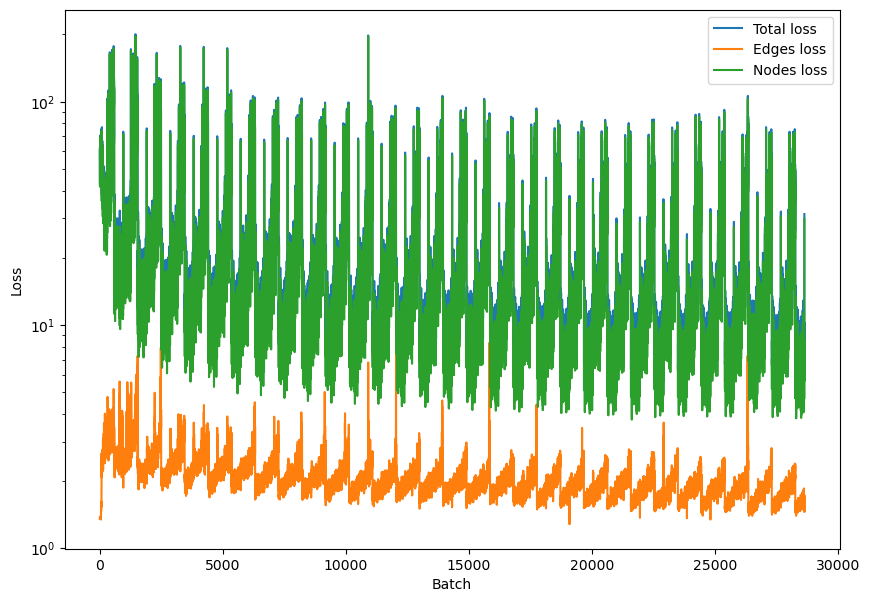

In [18]:
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (10, 7)})

plt.plot(losses, label="Total loss")
plt.plot(losses_edges, label="Edges loss")
plt.plot(losses_nodes, label="Nodes loss")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.show()